In [18]:
import pandas as pd
import numpy as np
import os
import re

from eval_plot_utils import parse_yml_pred,output_evaluation_outputs


## Virus phosphoproteome prediction
dms virus collection: `http://vanvalendgx1.caltech.edu:107/lab/tree/kinase_ml/data/virus_dms/collect_and_inspect_prefs.ipynb`

In [19]:
tape_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_long__virus__53ceb023016e.pkl',
                          return_logits=True).drop_duplicates()

In [20]:
pairs_aug = pd.read_csv('/ksi_ml/data/pairs_aug_virus.csv').iloc[:,1:].drop_duplicates()

In [21]:
tape_pred.columns = ['kinase_domain_seq','substrate_seq_15aa','probs','logits']
tape_pred = pd.merge(tape_pred,pairs_aug)
tape_pred = tape_pred.loc[:, ['kinase','kinase_gene','substrate','p_ind','p_aa','substrate_seq_15aa','probs','logits']]

In [22]:
df = tape_pred
df = df.loc[df['probs']>0.9,:]

In [23]:
group_cols = ["substrate", "substrate_seq_15aa", "p_ind", "p_aa"]

summary_df = (
    df
    .sort_values("logits", ascending=False)
    .groupby(group_cols, as_index=False)
    .head(10)
    .groupby(group_cols)[["kinase_gene", "logits",'probs']]  # <- list of cols
    .apply(lambda x: ",".join(f"{k}:{l:.4f}:{m:.4f}" for k, l ,m,in zip(x["kinase_gene"], x["logits"],x["probs"])))
    .reset_index(name="top10_kinase_logits")
)


In [24]:
summary_df_covid = summary_df.copy()

In [25]:
tape_pred = parse_yml_pred('/ksi_ml/code/evaluation/eval_outputs/exp_tape_bertbase_sep_v2_long__virus_dms__53ceb023016e.pkl',
                          return_logits=True).drop_duplicates()

In [26]:
pairs_aug = pd.read_csv('/ksi_ml/data/pairs_aug_virus_dms.csv').iloc[:,1:].drop_duplicates()

In [27]:
tape_pred.columns = ['kinase_domain_seq','substrate_seq_15aa','probs','logits']
tape_pred = pd.merge(tape_pred,pairs_aug)
tape_pred = tape_pred.loc[:, ['kinase','kinase_gene','substrate','p_ind','p_aa','substrate_seq_15aa','probs','logits']]

In [28]:
df = tape_pred

In [29]:
df = df.loc[df['probs']>0.9,:]

In [30]:
group_cols = ["substrate", "substrate_seq_15aa", "p_ind", "p_aa"]

summary_df = (
    df
    .sort_values("logits", ascending=False)
    .groupby(group_cols, as_index=False)
    .head(10)
    .groupby(group_cols)[["kinase_gene", "logits",'probs']]  # <- list of cols
    .apply(lambda x: ",".join(f"{k}:{l:.4f}:{m:.4f}" for k, l ,m,in zip(x["kinase_gene"], x["logits"],x["probs"])))
    .reset_index(name="top10_kinase_logits")
)


In [31]:
# note: did not find kinase phosphorylating HIV BF520_human
tape_pred.loc[tape_pred['substrate']== 'BF520_human',:].sort_values('logits',ascending = False).head(1)

,kinase,kinase_gene,substrate,p_ind,p_aa,substrate_seq_15aa,probs,logits
40597,P53350,PLK1,BF520_human,529,T,FLGAAGSTMGAASVT,0.057045,-2.84375


In [32]:
summary_df_virus_dms = summary_df.copy()

In [33]:
summary_df_virus_all = pd.concat([summary_df_virus_dms,summary_df_covid])

In [34]:
summary_df_virus_all.to_pickle('250118_virus_against_kinome_hits.pkl')

In [35]:
summary_df_virus_all.groupby('substrate').count()

,substrate_seq_15aa,p_ind,p_aa,top10_kinase_logits
substrate,,,,
NCAP_SARS2,24,24,24,24
ORF9B_SARS2,5,5,5,5
PR8_M1,3,3,3,3
Perth,6,6,6,6
R1AB_SARS2,6,6,6,6
SPIKE_SARS2,1,1,1,1
VME1_SARS2,4,4,4,4
WSN,29,29,29,29
ZIKA_E,18,18,18,18


In [36]:
summary_df_virus_all = summary_df_virus_all.loc[~summary_df_virus_all['substrate'].isin(['SPIKE_SARS2','VME1_SARS2','R1AB_SARS2']),:]

In [37]:
pkidb = pd.read_csv("/kinase_ml/code/tape_e2e_dms_inference//pkidb_2025-04-15.tsv",sep = '\t', encoding='latin-1')
pkidb_wtarget = pkidb.loc[(~pkidb["Name"].isna())&(~pkidb["Targets"].isna()),["Name","Phase","Targets","Kinase families",'FDA_approved']]
# assume df is your original dataframe
pkidb_wtarget = (
    pkidb_wtarget
    .assign(
        Targets=pkidb_wtarget["Targets"]
        .str.replace(r"<.*?>", "", regex=True)  # remove HTML like <br>(*)
        .str.split(r"\s*;\s*")                  # split on ';'
    )
    .explode("Targets")
    .rename(columns={"Targets": "Targets"})
    .reset_index(drop=True)
)



In [38]:
drugbank_uniprot_links = pd.read_csv("/kinase_ml/data/kinase_inhibitor_dbs/drugbank_uniprot_links.csv", engine='python')
drugbank_uniprot_links = drugbank_uniprot_links

In [39]:
human_kinome = pd.read_csv("/kinase_ml/data/human_kinome.csv")

In [40]:
drugbank_uniprot_links_kinase = pd.merge(drugbank_uniprot_links,human_kinome,left_on = "UniProt ID",right_on="UniprotID")

In [41]:
pkidb_wtarget_kinase = pd.concat([pd.merge(pkidb_wtarget,human_kinome,left_on = "Targets",right_on="gene"),
           pd.merge(pkidb_wtarget,human_kinome,left_on = "Targets",right_on="alias"),
           pd.merge(pkidb_wtarget,human_kinome,left_on = "Targets",right_on="HGNC")]).drop_duplicates().sort_values("Name")

In [42]:
drugbank_uniprot_links_kinase_min = drugbank_uniprot_links_kinase.loc[:,["Name","UniProt ID","gene"]]
drugbank_uniprot_links_kinase_min.columns = ["drug_name","kinase_acc","kinase_name"]

In [43]:
pkidb_wtarget_kinase_min = pkidb_wtarget_kinase.loc[:,["Name","UniprotID","gene"]]
pkidb_wtarget_kinase_min.columns = ["drug_name","kinase_acc","kinase_name"]

In [44]:
additional_drug = pd.DataFrame([{'BAY 1816032','O43683','BUB1'}])
additional_drug.columns = ['drug_name','kinase_acc','kinase_name']

In [45]:
drug_kinase_uniprot = pd.concat([pkidb_wtarget_kinase_min,drugbank_uniprot_links_kinase_min,additional_drug]).drop_duplicates()
# drug_kinase_uniprot = pd.concat([pkidb_wtarget_kinase_min]).drop_duplicates()

In [46]:
drug_kinase_uniprot = drug_kinase_uniprot.loc[~drug_kinase_uniprot['drug_name'].isin(['ATP','Adenine','1']),:]

In [47]:
drug_kinase_uniprot.to_pickle("./drug_kinase_uniprot.pkl")

In [48]:
drug_kinase_uniprot.loc[drug_kinase_uniprot['kinase_name']=='CK1a']

,drug_name,kinase_acc,kinase_name
1294,Fostamatinib,P48729,CK1a


In [49]:
dms_candidates_inference_kinbertv2 = summary_df_virus_all

In [50]:
dms_candidates_inference_kinbertv2.columns = ['substrate', 'substrate_seq_15aa', 'p_ind', 'wt_aa',
       'pred_kinase_prob']

In [51]:
dms_candidates_inference_kinbertv2["pred_kinase"] = dms_candidates_inference_kinbertv2["pred_kinase_prob"].apply(lambda s: [elem.strip('\'').split(":")[0] for elem in s.split(',') ])

In [52]:
import pandas as pd
import ast
import re

def _as_list(x):
    """Robustly coerce a cell that might be a real list or a string repr of a list into a Python list."""
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return []
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        s = x.strip()
        if not s:
            return []
        # Try literal eval for things like "['A','B']" or "['A:1.2:0.9', ...]"
        try:
            v = ast.literal_eval(s)
            return v if isinstance(v, list) else [v]
        except Exception:
            # Fallback: try to split something like "[A, B, C]" or "A, B, C"
            s = s.strip("[]")
            parts = [p.strip().strip("'").strip('"') for p in s.split(",")]
            return [p for p in parts if p]
    return [x]

def _norm_kinase_name(name: str) -> str:
    """
    Normalize kinase names to improve matching.
    - Uppercase
    - Remove spaces/hyphens/underscores
    - Keep alnum only
    """
    if name is None:
        return ""
    s = str(name).strip().upper()
    s = re.sub(r"[\s\-_]+", "", s)
    s = re.sub(r"[^A-Z0-9]", "", s)
    return s

def add_matched_drug(hits_df: pd.DataFrame,
                     drug_df: pd.DataFrame,
                     pred_col: str = "pred_kinase",
                     drug_kinase_col: str = "kinase_name",
                     drug_name_col: str = "drug_name",
                     out_col: str = "matched_drug") -> pd.DataFrame:
    """
    Adds a column where each predicted kinase is mapped to all matching drugs.

    Output per row is a list of strings like:
      ["MAP3K5:Selonsertib", "TRKA:Entrectinib;Larotrectinib", "WEE1B:"]
    """

    # 1) Build mapping: normalized kinase_name -> sorted unique list of drugs
    d = drug_df.copy()
    d["_kin_norm"] = d[drug_kinase_col].map(_norm_kinase_name)
    d = d[d["_kin_norm"].astype(bool)].copy()

    kin_to_drugs = (
        d.groupby("_kin_norm")[drug_name_col]
         .apply(lambda s: sorted(pd.unique([x for x in s.dropna().astype(str)])))
         .to_dict()
    )

    # 2) For each row, parse predicted kinases list and map
    def _map_row(pred_val):
        kin_list = _as_list(pred_val)
        out = []
        for kin in kin_list:
            kin_str = str(kin).strip()
            kin_norm = _norm_kinase_name(kin_str)
            drugs = kin_to_drugs.get(kin_norm, [])
            if drugs:
                out.append(f"{kin_str}:{';'.join(drugs)}")
            else:
                out.append(f"{kin_str}:")
        return out

    out_df = hits_df.copy()
    out_df[out_col] = out_df[pred_col].apply(_map_row)
    return out_df



In [53]:
hits_df = dms_candidates_inference_kinbertv2
drug_df =drug_kinase_uniprot

dms_candidates_inference_kinbertv2 = add_matched_drug(hits_df, drug_df)

In [54]:
dms_candidates_inference_kinbertv2["substrate"].drop_duplicates()

0          PR8_M1
3           Perth
9             WSN
38         ZIKA_E
0      NCAP_SARS2
24    ORF9B_SARS2
Name: substrate, dtype: object

In [55]:
# dms_candidates_inference_kinbertv1.loc[dms_candidates_inference_kinbertv1["substrate"]=="ZIKA_E",:]

In [56]:
import pandas as pd
import ast
import re

def _as_list(x):
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return []
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        s = x.strip()
        if not s:
            return []
        try:
            v = ast.literal_eval(s)
            return v if isinstance(v, list) else [v]
        except Exception:
            s = s.strip("[]")
            parts = [p.strip().strip("'").strip('"') for p in s.split(",")]
            return [p for p in parts if p]
    return [x]

_prob_re = re.compile(r"^\s*(?P<kin>[^:]+)\s*:\s*(?P<logit>-?\d+(\.\d+)?)\s*:\s*(?P<prob>\d+(\.\d+)?)\s*$")

def _parse_prob_item(item: str):
    """
    Parses 'KINASE:logit:prob' -> (kinase, logit(float), prob(float)).
    Returns None if not parseable.
    """
    m = _prob_re.match(str(item))
    if not m:
        return None
    return m.group("kin").strip(), float(m.group("logit")), float(m.group("prob"))

def _has_any_drug(matched_item: str) -> bool:
    """
    matched_item like 'PKCi:Bisindolylmaleimide I;Tamoxifen' or 'CK1a:'.
    True if there is any non-empty drug string after ':'.
    """
    s = str(matched_item)
    if ":" not in s:
        return False
    _, rhs = s.split(":", 1)
    return bool(rhs.strip())

def filter_hits_by_logit_and_drug(df: pd.DataFrame, logit_min: float = 2.0) -> pd.DataFrame:
    """
    Keeps rows where at least one predicted kinase satisfies:
      - logit >= logit_min (from pred_kinase_prob items)
      - matched_drug has >=1 drug for that kinase (not just 'KINASE:')
    Adds:
      - passing_kinases (list)
      - passing_drugs (list of 'KINASE:drugA;drugB')
    """
    out = df.copy()

    # Ensure lists
    out["_prob_list"] = out["pred_kinase_prob"].apply(_as_list)
    out["_drug_list"] = out["matched_drug"].apply(_as_list)

    def per_row(prob_list, drug_list):
        # map kinase -> (logit, prob)
        kin2score = {}
        for it in prob_list:
            parsed = _parse_prob_item(it)
            if parsed:
                kin, logit, prob = parsed
                kin2score[kin] = (logit, prob)

        passing_kin = []
        passing_drug_entries = []

        for d in drug_list:
            d = str(d)
            kin = d.split(":", 1)[0].strip() if ":" in d else d.strip()
            score = kin2score.get(kin)
            if score is None:
                continue
            logit, _ = score
            if logit >= logit_min and _has_any_drug(d):
            # if logit >= logit_min:
                passing_kin.append(kin)
                passing_drug_entries.append(d)

        return passing_kin, passing_drug_entries

    tmp = out.apply(lambda r: per_row(r["_prob_list"], r["_drug_list"]), axis=1, result_type="expand")
    out["passing_kinases"] = tmp[0]
    out["passing_drugs"] = tmp[1]

    # Filter: at least one passing kinase+drug
    out = out[out["passing_drugs"].map(len) > 0].copy()

    # (optional) drop helpers
    out.drop(columns=["_prob_list", "_drug_list"], inplace=True)

    return out




In [57]:
# usage:
filtered_df = filter_hits_by_logit_and_drug(dms_candidates_inference_kinbertv2, logit_min=3)
filtered_df['substrate'].drop_duplicates()
sub_nam_map = {'WSN':'influenza \n H1',
'BF520_human':'HIV \n human',
'BF520_rhesus':'HIV \n rhesus',
'Perth': 'H3N2',
'PR8_M1':'influenza \n M1',
'ZIKA_E':'ZIKA E',
              'NCAP_SARS2':' SARS2:Nucleocapsid',
              'ORF9B_SARS2':'SARS2:ORF9b',}

In [58]:
filtered_df['substrate'] = filtered_df['substrate'].apply(lambda s:sub_nam_map[s])

In [59]:
import pandas as pd
import ast
import re

def _as_list(x):
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return []
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        try:
            v = ast.literal_eval(x)
            return v if isinstance(v, list) else [v]
        except Exception:
            return [s.strip() for s in x.strip("[]").split(",") if s.strip()]
    return [x]

# parse "KIN:logit:prob"
_PROB_RE = re.compile(r"^\s*([^:]+)\s*:\s*([-+]?\d*\.?\d+)\s*:\s*")

def extract_logit_map(prob_list):
    """
    Returns dict kinase -> logit
    """
    d = {}
    for item in _as_list(prob_list):
        m = _PROB_RE.match(str(item))
        if m:
            d[m.group(1).strip()] = float(m.group(2))
    return d

def top_logit_row(row):
    passing = _as_list(row["passing_kinases"])
    if not passing:
        return None

    logit_map = extract_logit_map(row["pred_kinase_prob"])

    # restrict to passing kinases only
    scored = [(k, logit_map.get(k, float("-inf"))) for k in passing]
    top_kinase, top_logit = max(scored, key=lambda x: x[1])

    # find matching drug entry
    top_drug = None
    for d in _as_list(row["passing_drugs"]):
        if str(d).startswith(f"{top_kinase}:"):
            top_drug = d
            break

    return pd.Series({
        "top_kinase": top_kinase,
        "top_logit": top_logit,
        "top_drug": top_drug
    })



In [60]:
# apply
top_df = filtered_df.copy()
top_df[["top_kinase", "top_logit", "top_drug"]] = top_df.apply(top_logit_row, axis=1)

# keep only rows with a valid top kinase
top_df = top_df.dropna(subset=["top_kinase"]).reset_index(drop=True)
# top_df = top_df.groupby('substrate').head(2)
top_df.to_csv('./250118_virus_against_kinome_hits_with_drug.csv')

In [61]:
import pandas as pd
import ast
import re
from plotnine import *

def _as_list(x):
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return []
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        s = x.strip()
        if not s:
            return []
        try:
            v = ast.literal_eval(s)
            return v if isinstance(v, list) else [v]
        except Exception:
            s = s.strip("[]")
            parts = [p.strip().strip("'").strip('"') for p in s.split(",")]
            return [p for p in parts if p]
    return [x]

_prob_re = re.compile(r"^\s*(?P<kin>[^:]+)\s*:\s*(?P<logit>-?\d+(\.\d+)?)\s*:\s*(?P<prob>\d+(\.\d+)?)\s*$")

def parse_prob_list(prob_list):
    """Return dict kinase -> logit from ['KIN:logit:prob', ...]."""
    d = {}
    for it in _as_list(prob_list):
        m = _prob_re.match(str(it))
        if m:
            d[m.group("kin").strip()] = float(m.group("logit"))
    return d

def parse_passing_drugs(passing_drugs):
    """
    From ['KIN:DrugA;DrugB', 'KIN2:DrugC', ...]
    return rows of (kinase, drug). Skips empty drug strings.
    """
    rows = []
    for it in _as_list(passing_drugs):
        s = str(it)
        if ":" not in s:
            continue
        kin, rhs = s.split(":", 1)
        kin = kin.strip()
        rhs = rhs.strip()
        if not rhs:
            continue
        for drug in rhs.split(";"):
            drug = drug.strip()
            if drug:
                rows.append((kin, drug))
    return rows

def make_psite_label(df):
    # psite label like "S51" etc.
    return   df["wt_aa"].astype(str) + df["p_ind"].astype(str)
def build_logit_long(filtered_df):
    df = filtered_df.copy()
    df["psite"] = make_psite_label(df)

    # collect all kinases (columns) across filtered_df to keep x consistent
    all_kinases = sorted({k for ks in df["top_kinase"].apply(_as_list) for k in ks})

    rows = []
    for _, r in df.iterrows():
        logit_map = parse_prob_list(r["pred_kinase_prob"])
        for kin in _as_list(r["top_kinase"]):
            if kin in logit_map:
                rows.append({
                    "substrate": r["substrate"],
                    "psite": r["psite"],
                    "kinase": kin,
                    "logit": logit_map[kin],
                })

    long = pd.DataFrame(rows)
    if long.empty:
        return long

    # factor ordering (keeps all kinases consistent across facets)
    long["kinase"] = pd.Categorical(long["kinase"], categories=all_kinases, ordered=True)

    # optional: keep psites ordered within each substrate by numeric position
    # (plotnine uses global factor levels, so simplest is leave as string or sort by p_ind)
    return long



In [62]:
top_df['top_kinase'] = top_df['pred_kinase']
top_df['top_drug'] = top_df['matched_drug']
logit_long = build_logit_long(top_df)

In [63]:
searched_links = pd.read_csv('./claude_evidence_kinase_drug_virus.csv')
searched_links_examples = searched_links.loc[~searched_links['virus_drug_evidence'].isna(),:].groupby(['virus','kinase','drug','sequence']).head(1)

In [64]:
logit_long.loc[logit_long['psite']=='S202']

,substrate,psite,kinase,logit
482,SARS2:Nucleocapsid,S202,NEK10,3.4531
483,SARS2:Nucleocapsid,S202,ICK,3.1406
484,SARS2:Nucleocapsid,S202,PCTAIRE1,3.0625
485,SARS2:Nucleocapsid,S202,MOK,3.0000
486,SARS2:Nucleocapsid,S202,PCTAIRE2,2.7812
487,SARS2:Nucleocapsid,S202,GSK3B,2.7031
488,SARS2:Nucleocapsid,S202,GSK3A,2.5469
489,SARS2:Nucleocapsid,S202,CDC7,2.4531
490,SARS2:Nucleocapsid,S202,CDKL2,2.3750
491,SARS2:Nucleocapsid,S202,PCTAIRE3,2.3594


In [65]:
###### for demo example only
logit_long = pd.merge(logit_long,searched_links_examples,left_on = ['substrate','kinase'],right_on = ['virus','kinase'])
logit_long = logit_long.iloc[:,[0,1,2,3]]
logit_long  = logit_long.drop_duplicates().groupby(['substrate','kinase']).head(2)
logit_long.columns = ['substrate','psite','kinase','logit']

flu_top_df = top_df.iloc[[1,6,9],:]
logit_long_flu = build_logit_long(flu_top_df).groupby(['substrate','psite']).head(1)
logit_long = pd.concat([logit_long,logit_long_flu])

In [66]:
logit_long_tmp = logit_long.copy()


In [120]:
def complete_with_zeros(df, kinase_order):
    """
    Ensures every (substrate, psite, kinase) exists.
    Missing logit values are filled with 0.
    """
    df = df.copy()

    # all psites per substrate
    idx = (
        df[["substrate", "psite"]]
        .drop_duplicates()
        .assign(key=1)
        .merge(
            pd.DataFrame({"kinase": kinase_order, "key": 1}),
            on="key",
            how="outer"
        )
        .drop(columns="key")
    )

    out = (
        idx.merge(
            df,
            on=["substrate", "psite", "kinase"],
            how="left"
        )
    )

    out["logit"] = out["logit"].fillna(0)

    return out


GLOBAL_KINASE_ORDER = (
    logit_long_tmp["kinase"]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)
logit_long_filled = complete_with_zeros(
    logit_long_tmp,
    kinase_order=GLOBAL_KINASE_ORDER
)

p1 = (
    ggplot(logit_long_filled, aes("kinase", "psite", fill="logit"))
    + geom_tile(color='white', size=0.2)

    # 🔒 shared kinase axis, no padding
    + scale_x_discrete(expand=(0, 0))
    + scale_y_discrete(expand=(0, 0))
    + scale_fill_gradient(
    low="lightgray",
        high="darkred",
    limits=(0, logit_long_filled["logit"].max()),
    expand=(0, 0)
)
    # ✅ facet by substrate, grouping y-values per substrate
    + facet_grid(
        "substrate ~ .",
        scales="free_y",
        space="free_y"
    )

    + labs(x="Kinase", y="P-site", fill="Logit", title="")
    + theme_minimal()
    
    + theme(
        panel_background=element_rect(fill='white', color='white', size=0.5, linetype='solid'),
                # panel_grid_major=element_line(size=0.5, linetype='solid', color='lightgray'),
                panel_grid_minor=element_blank(),

        axis_text_x=element_text(size=15, color="black", rotation=90,weight = 'bold'),
        axis_text_y=element_text(size=15, color="black",weight = 'bold'),

        axis_ticks_x=element_line(size=0.5, color="white"),
        axis_ticks_y=element_line(size=0.5, color="white"),
        strip_text_y=element_text(size=18, weight="bold",rotation = 0),
        figure_size=(15, 15),
        legend_position="right",
        legend_key_height=50,
        legend_key_width=10
    )
    + coord_cartesian(expand=False)

)


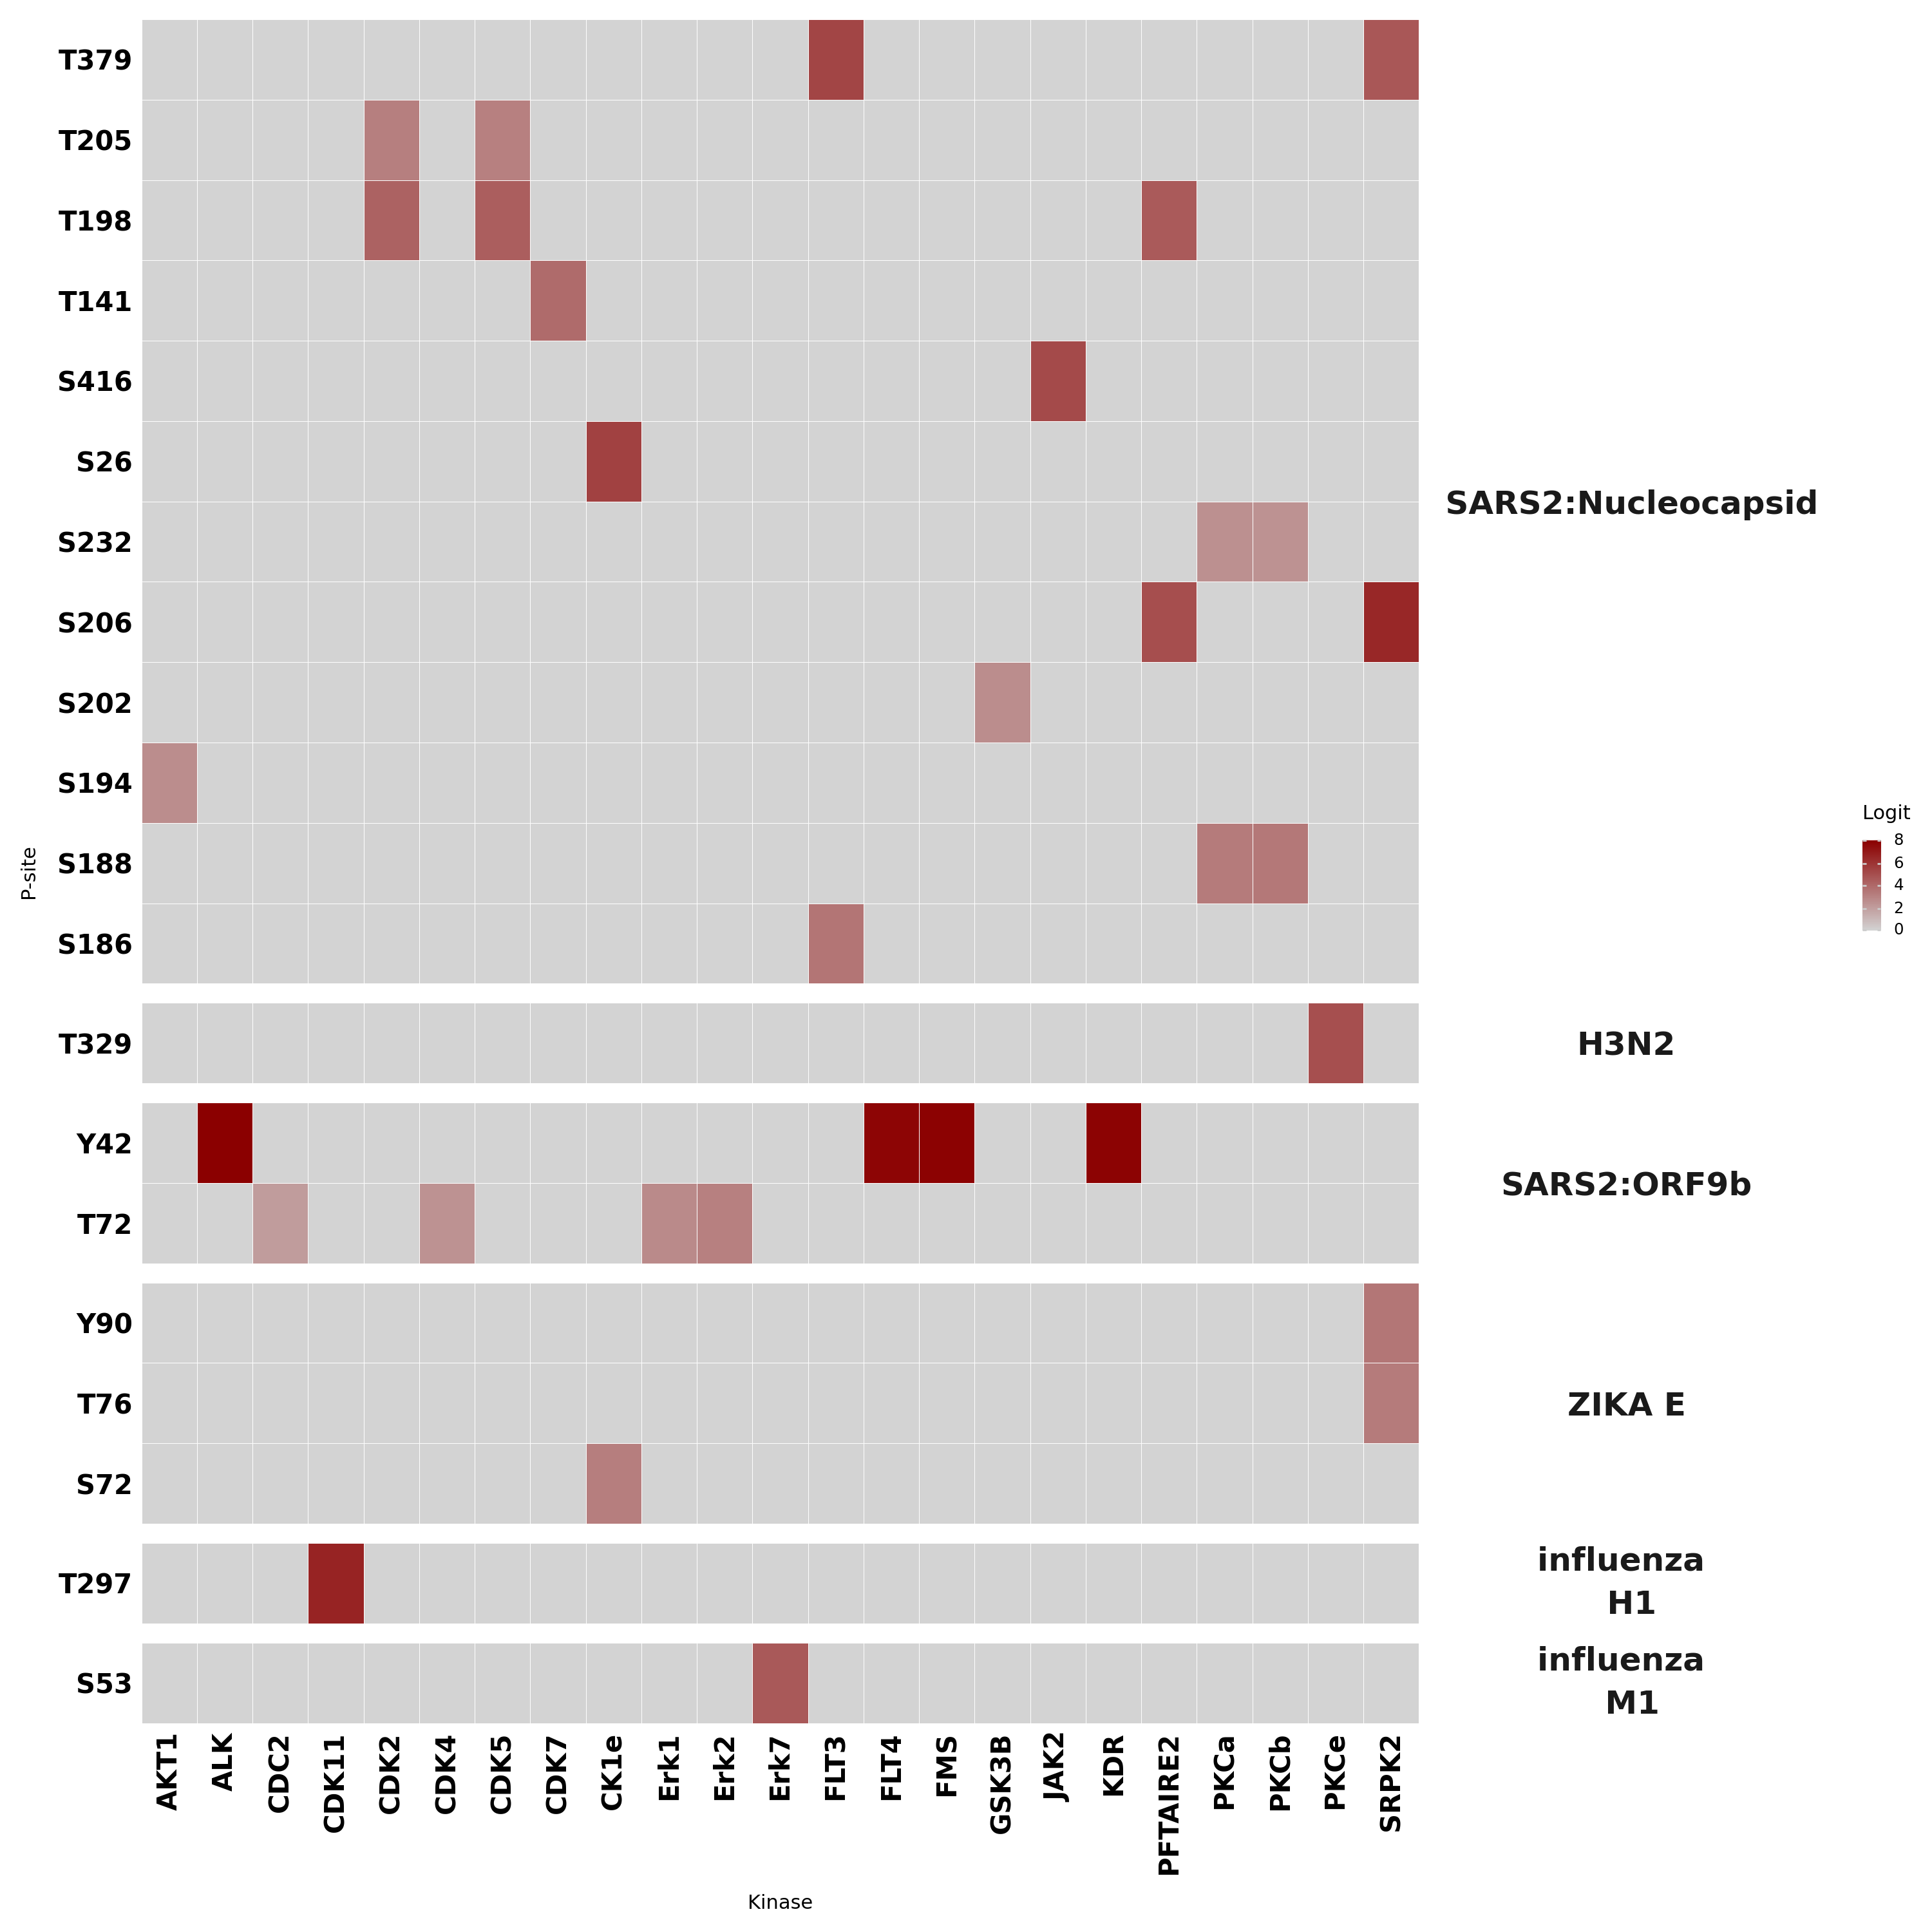

In [121]:

p1

In [69]:
# top_df["top_drug"] = (
#     top_df["top_drug"]
#     .str.split(":", n=1).str[0] + ":" +
#     top_df["top_drug"]
#     .str.split(":", n=1).str[1]
#     .str.split(";", n=1).str[0]
# )

In [70]:
import pandas as pd

def build_drug_kinase_binary_filled(filtered_df):
    df = filtered_df.copy()

    # local kinase order (only from data)
    kinase_order = (
        df["top_kinase"]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    rows = []
    for _, r in df.iterrows():
        # top_drug like "KIN:DrugA;DrugB"
        for kin, drug in parse_passing_drugs(r["top_drug"]):
            rows.append({
                "kinase": str(kin),
                "drug": str(drug),
                "hit": 1
            })

    long = pd.DataFrame(rows)
    if long.empty:
        return long

    # ensure uniqueness + deterministic hit
    long = (
        long
        .groupby(["drug", "kinase"], as_index=False)["hit"]
        .max()
    )

    # ---- Complete the drug × kinase grid ----
    drugs = pd.DataFrame({"drug": long["drug"].unique()})
    kins  = pd.DataFrame({"kinase": kinase_order})

    drugs["key"] = 1
    kins["key"] = 1

    full = (
        drugs.merge(kins, on="key")
             .drop(columns="key")
    )

    out = full.merge(long, on=["drug", "kinase"], how="left")
    out["hit"] = out["hit"].fillna(0).astype(int)

    # lock kinase axis ordering
    out["kinase"] = pd.Categorical(
        out["kinase"],
        categories=kinase_order,
        ordered=True
    )

    return out



In [71]:
# #full execution
# drug_long = build_drug_kinase_binary_filled(top_df)

In [72]:
# for example demo round

def melt_kinase_drug_hits(df):
    """
    Build a melted dataframe with columns:
    substrate, psite, kinase, drug, logit, prob, hit
    """

    rows = []

    for _, r in df.iterrows():
        substrate = r["substrate"]
        psite = f"{r['wt_aa']}{int(r['p_ind'])}"

        # ---- parse pred_kinase_prob ----
        # format: kinase:logit:prob,kinase2:logit2:prob2
        kp = {}
        for item in str(r["pred_kinase_prob"]).split(","):
            try:
                k, logit, prob = item.split(":")
                kp[k] = {
                    "logit": float(logit),
                    "prob": float(prob),
                }
            except ValueError:
                continue

        # ---- parse matched_drug ----
        # format: [IRAK1:Fostamatinib, PKR:Fostamatinib;Tamoxifen]
        md = {}
        
        md_list = r["matched_drug"]
        # print(md_list)
        for x in md_list:
            try:
                k, drugs = x.split(":", 1)
                md[k] = [d for d in drugs.split(";") if d]
            except Exception:
                pass

        # ---- build melted rows ----
        for kinase, vals in kp.items():
            drugs = md.get(kinase, [""])
            for drug in drugs:
                rows.append(
                    {
                        "substrate": substrate,
                        "psite": psite,
                        "kinase": kinase,
                        "drug": drug,
                        "logit": vals["logit"],
                        "prob": vals["prob"],
                        "hit": 1,
                    }
                )

    return pd.DataFrame(rows)


In [73]:
drug_long = melt_kinase_drug_hits(top_df)

In [74]:
drug_long_count = drug_long.drop_duplicates(['kinase','drug']).groupby(['drug']).count().reset_index().iloc[:,:2].sort_values('substrate')
drug_long_count.columns = ['drug','nsub']

In [75]:
drug_long = pd.merge(drug_long,drug_long_count)

In [76]:
drug_long.loc[drug_long['kinase']=='CK1e',:]

,substrate,psite,kinase,drug,logit,prob,hit,nsub
673,ZIKA E,S72,CK1e,Seliciclib,3.2656,0.9697,1,6
674,ZIKA E,S72,CK1e,Umbralisib,3.2656,0.9697,1,1
957,SARS2:Nucleocapsid,S26,CK1e,Seliciclib,5.5625,0.9969,1,6
958,SARS2:Nucleocapsid,S26,CK1e,Umbralisib,5.5625,0.9969,1,1


In [77]:
drug_long = drug_long.drop_duplicates().sort_values('nsub').loc[drug_long['kinase'].isin(logit_long_tmp['kinase']),:].groupby(['kinase','substrate']).head(2).sort_values('kinase')

In [78]:
def fill_missing_hits(
     long_df: pd.DataFrame,):


    required = {"kinase", "drug", "hit"}
    missing = required - set(long_df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    df = long_df.copy()

    # Unique kinases and drugs
    kinases = pd.DataFrame({"kinase": df["kinase"].dropna().unique()})
    drugs = pd.DataFrame({"drug": df["drug"].dropna().unique()})

    # Cartesian product: kinase × drug
    full = kinases.merge(drugs, how="cross")

    # Observed pairs (collapse duplicates → hit=1)
    observed = (
        df[["kinase", "drug", "hit"]]
        .groupby(["kinase", "drug"], as_index=False)
        .agg(hit=("hit", "max"))
    )

    # Merge and fill missing
    out = full.merge(observed, on=["kinase", "drug"], how="left")
    out["hit"] = out["hit"].fillna(0).astype(int)

    return out

In [79]:
22*22

484

In [80]:
drug_long = fill_missing_hits(drug_long)

In [81]:
drug_long.drop_duplicates()

,kinase,drug,hit
0,AKT1,"Inositol 1,3,4,5-Tetrakisphosphate",1
1,AKT1,Genistein,1
2,AKT1,Alectinib,0
3,AKT1,Lorlatinib,0
4,AKT1,Ensartinib,0
...,...,...,...
963,SRPK2,Ellagic acid,0
964,SRPK2,alpha-Tocopherol succinate,0
965,SRPK2,KAI-1455,0
966,SRPK2,Bryostatin 1,0


In [82]:
drug_long.loc[drug_long['drug']=='XL820',:]

,kinase,drug,hit
33,AKT1,XL820,0
77,ALK,XL820,0
121,CDC2,XL820,0
165,CDK2,XL820,0
209,CDK4,XL820,0
253,CDK5,XL820,0
297,CDK7,XL820,0
341,CK1e,XL820,0
385,Erk1,XL820,0
429,Erk2,XL820,0


In [83]:
# truncate drug labels AFTER building the grid (so truncation doesn’t collapse distinct drugs)
drug_long["drug_lbl"] = drug_long["drug"].apply(lambda s: s[:10] + "..." if len(s) > 10 else s)

# for manual fill scale
drug_long["hit"] = drug_long["hit"].astype(str)   # "0"/"1"

from plotnine import *


p2 = (
    ggplot(drug_long, aes("kinase", "drug_lbl", fill="hit"))
    + geom_tile(color='white', size=0.2)
    + scale_x_discrete(drop=True, expand=(0, 0))
    + scale_y_discrete(expand=(0, 0))
    + scale_fill_manual(
        values={"0": "lightgray", "1": "navy"},
        breaks=["1", "0"],
        labels=["Target", "No target"]
    )
    + labs(x="Kinase", y="Drug", fill="Targets")
    + theme_bw()
    + theme(
        panel_background=element_rect(fill="white"),
        axis_text_x=element_text(size=15, color="black", weight="bold", rotation=90),
        axis_text_y=element_text(size=15, color="black", weight="bold"),
        legend_position="right",
        figure_size=(20, 15),
        axis_ticks_length=0,
        panel_spacing=0.15,
    )
    + coord_fixed(ratio=1)
)

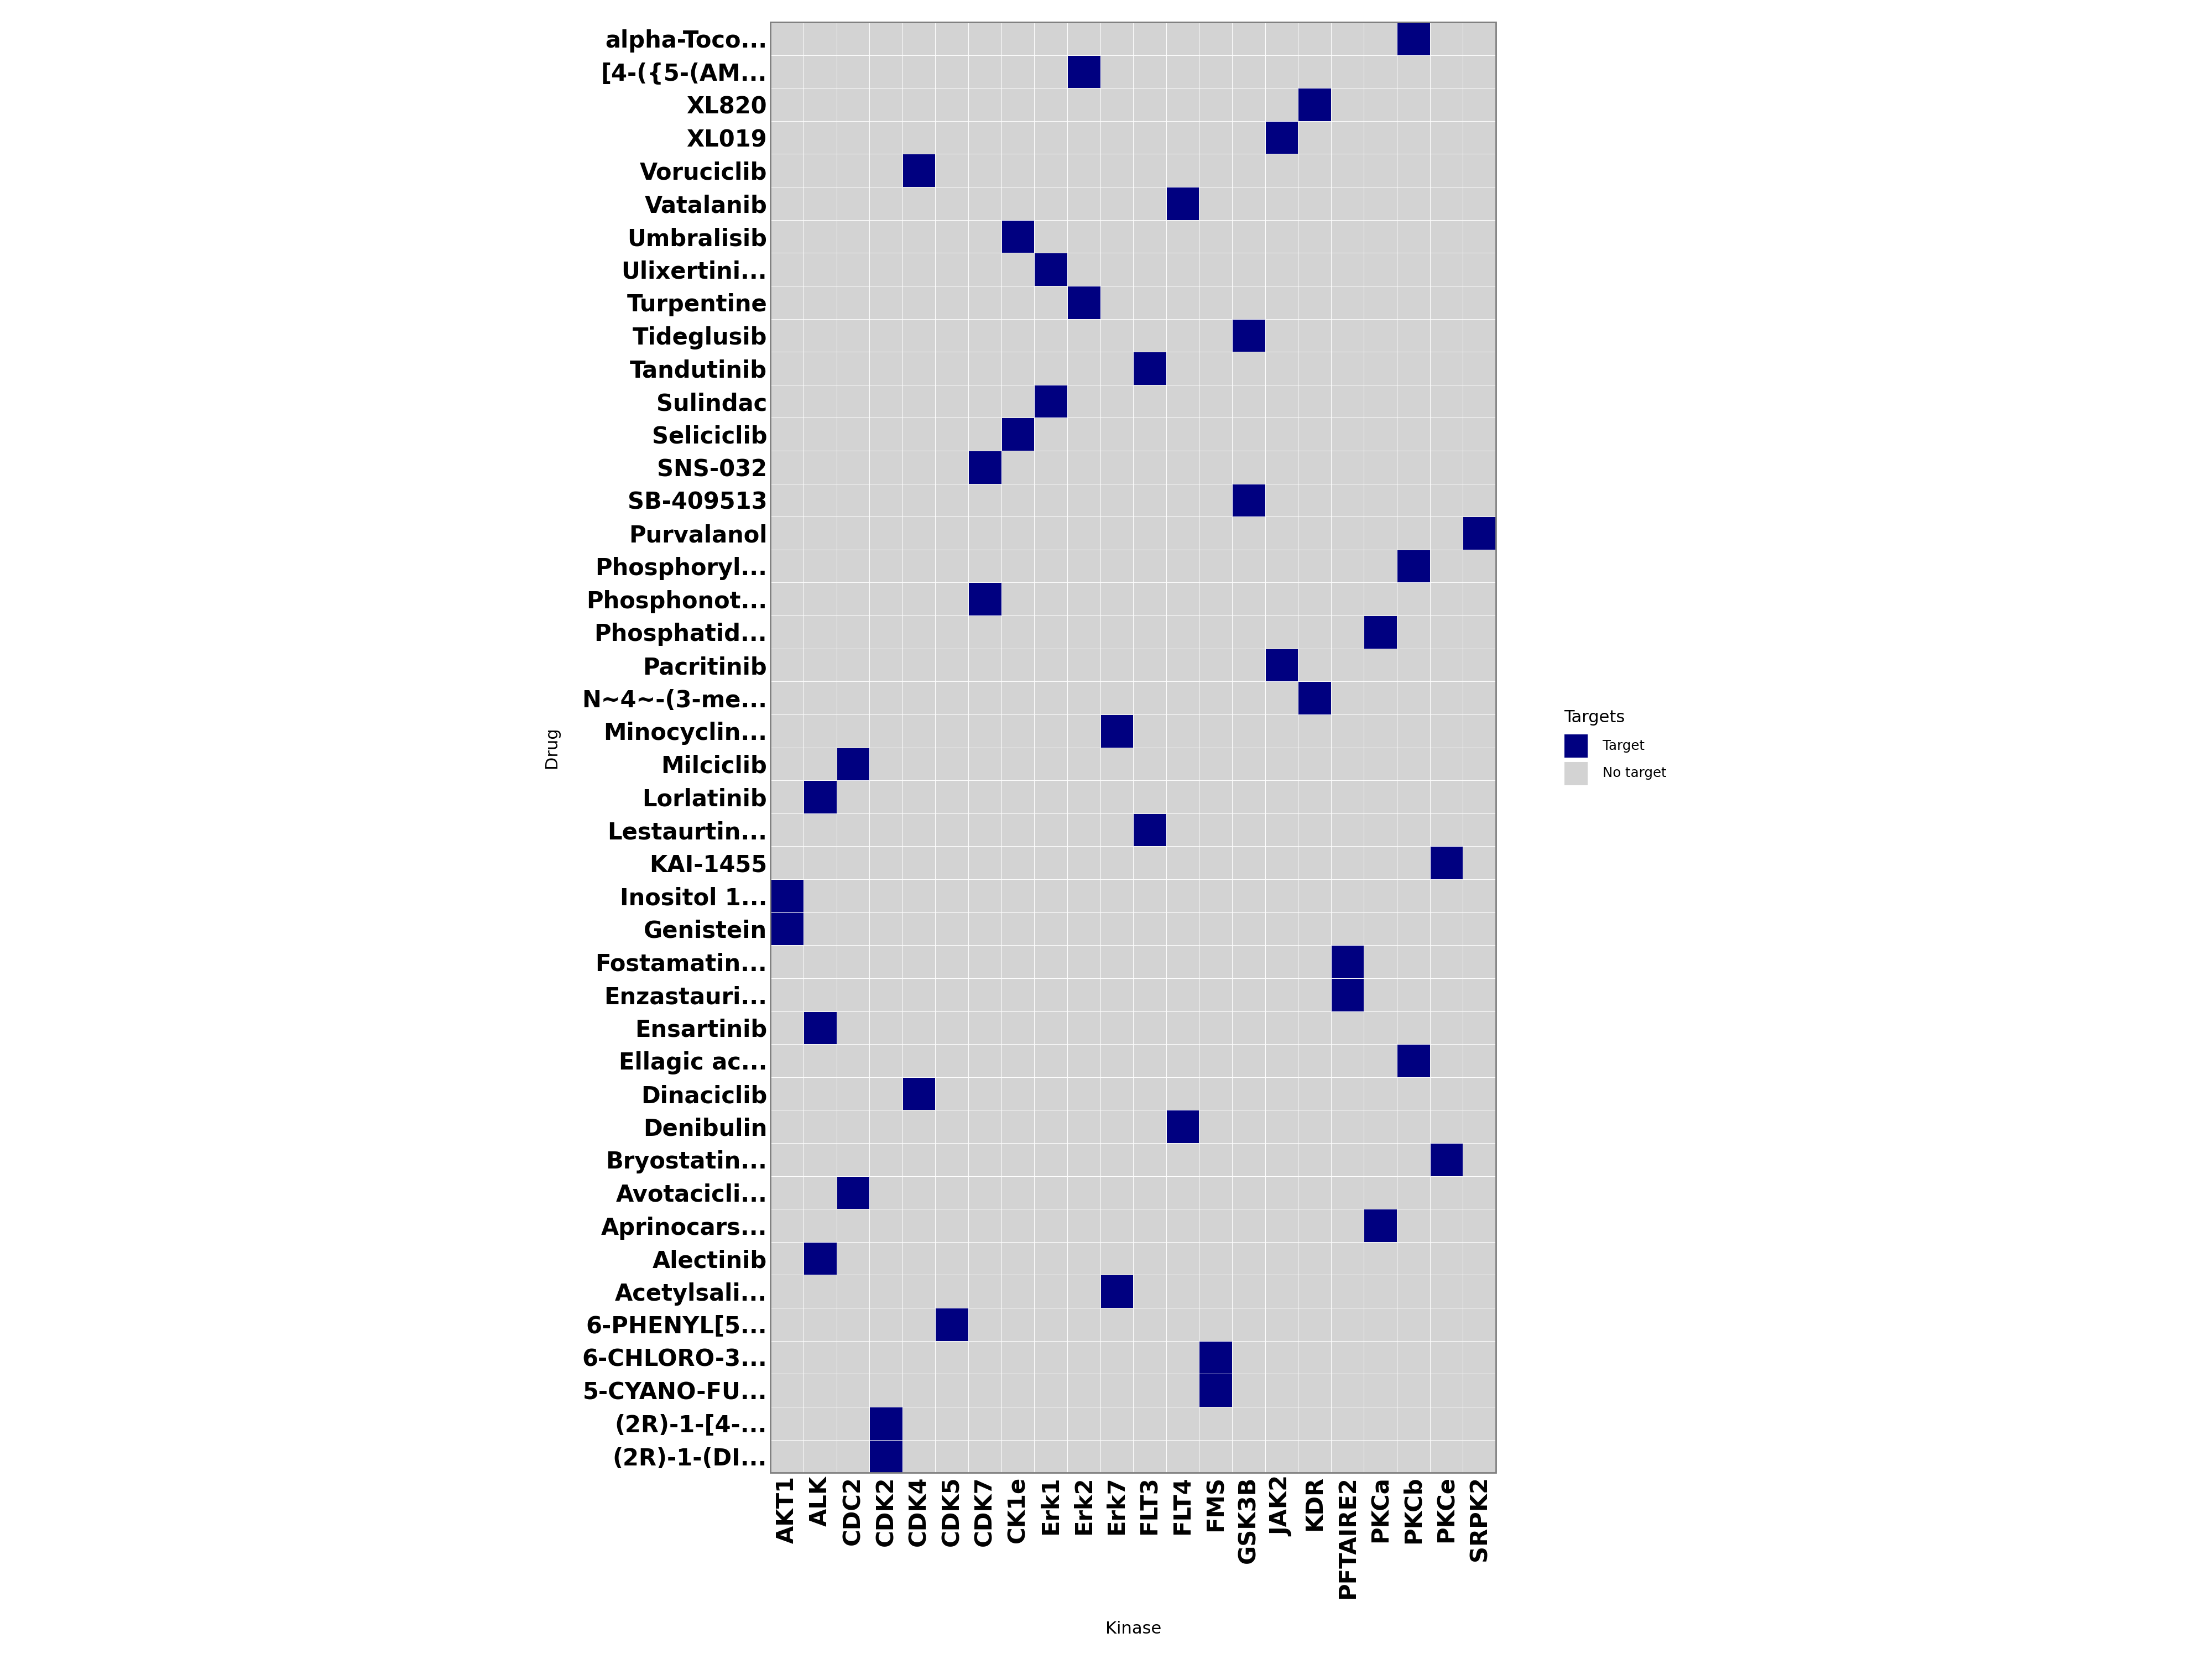

In [84]:
p2.show()


In [92]:
import pandas as pd

def parse_drug_list_from_top_drug(top_drug):
    """
    top_drug: string like "KIN:DrugA;DrugB" or None
    returns ["DrugA","DrugB"]
    """
    if top_drug is None or (isinstance(top_drug, float) and pd.isna(top_drug)):
        return []
    s = str(top_drug)
    if ":" not in s:
        return []
    rhs = s.split(":", 1)[1].strip()
    if not rhs:
        return []
    return [d.strip() for d in rhs.split(";") if d.strip()]

def build_logit_long_by_drug(filtered_df):
    df = filtered_df.copy()
    df["psite"] = make_psite_label(df)

    rows = []
    for _, r in df.iterrows():
        logit_map = parse_prob_list(r["pred_kinase_prob"])  # kinase -> logit

        # top kinase is a scalar string in your top_df
        kin = str(r["top_kinase"]) if pd.notna(r["top_kinase"]) else None
        if not kin or kin not in logit_map:
            continue

        logit_val = logit_map[kin]

        # explode drugs for this top kinase
        for drug in parse_drug_list_from_top_drug(r["top_drug"]):
            rows.append({
                "substrate": r["substrate"],
                "psite": r["psite"],
                "drug": drug,
                "logit": logit_val
            })

    long = pd.DataFrame(rows)
    if long.empty:
        return long

    # if duplicates happen, keep max logit (safe)
    long = long.groupby(["substrate", "psite", "drug"], as_index=False)["logit"].max()
    return long

def complete_with_zeros_drug(df):
    df = df.copy()

    drug_order = (
        df["drug"].dropna().astype(str).unique().tolist()
    )

    idx = (
        df[["substrate", "psite"]]
        .drop_duplicates()
        .assign(key=1)
        .merge(pd.DataFrame({"drug": drug_order, "key": 1}), on="key", how="outer")
        .drop(columns="key")
    )

    out = idx.merge(df, on=["substrate", "psite", "drug"], how="left")
    out["logit"] = out["logit"].fillna(0)

    # lock x ordering inside the plot (optional but nice)
    out["drug"] = pd.Categorical(out["drug"], categories=drug_order, ordered=True)
    return out, drug_order


In [85]:
# for demo only
virus_drug_long = pd.merge(logit_long,drug_long.loc[drug_long['hit']=='1',:],on = 'kinase').loc[:,['drug','substrate','psite','logit','kinase']].drop_duplicates()

In [86]:
virus_drug_long = virus_drug_long.groupby(['psite','substrate','kinase']).head(2)

In [93]:
logit_drug_filled, DRUG_ORDER = complete_with_zeros_drug(virus_drug_long)

In [94]:
logit_drug_filled.loc[logit_drug_filled['drug']=='Erk1']

,substrate,psite,drug,logit,kinase


In [95]:
# #full execution
# logit_drug_long = build_logit_long_by_drug(top_df)
# logit_drug_filled, DRUG_ORDER = complete_with_zeros_drug(logit_drug_long)

In [118]:
from plotnine import *
def shorten_drug_label(s, max_len=12):
    s = str(s)
    return s if len(s) <= max_len else s[:max_len] + "…"

p_drug = (
    ggplot(logit_drug_filled, aes("drug", "psite", fill="logit"))
    + geom_tile(color="white", size=0.2)
    + scale_x_discrete(
        expand=(0, 0),
        drop=False,
        labels=lambda labs: [shorten_drug_label(x, 12) for x in labs]
    )
    + scale_y_discrete(expand=(0, 0))
    + scale_fill_gradient(
    low="lightgray",
        high="purple",
    limits=(0, logit_long_filled["logit"].max()/2),
    expand=(0, 0)
)
    + facet_grid("substrate ~ .", scales="free_y", space="free_y")
    + coord_cartesian(expand=False)
    + labs(x="Drug", y="P-site", fill="Logit")
    + theme_minimal()
   + theme(
        panel_background=element_rect(fill="white"),
        axis_text_x=element_text(size=15, color="black", weight="bold", rotation=90),
        axis_text_y=element_text(size=15, color="black", weight="bold"),
        legend_position="right",
       strip_text_y=element_text(size=18, weight="bold",rotation = 0),
        figure_size=(20, 10),
    ) + coord_cartesian(expand=False)
)


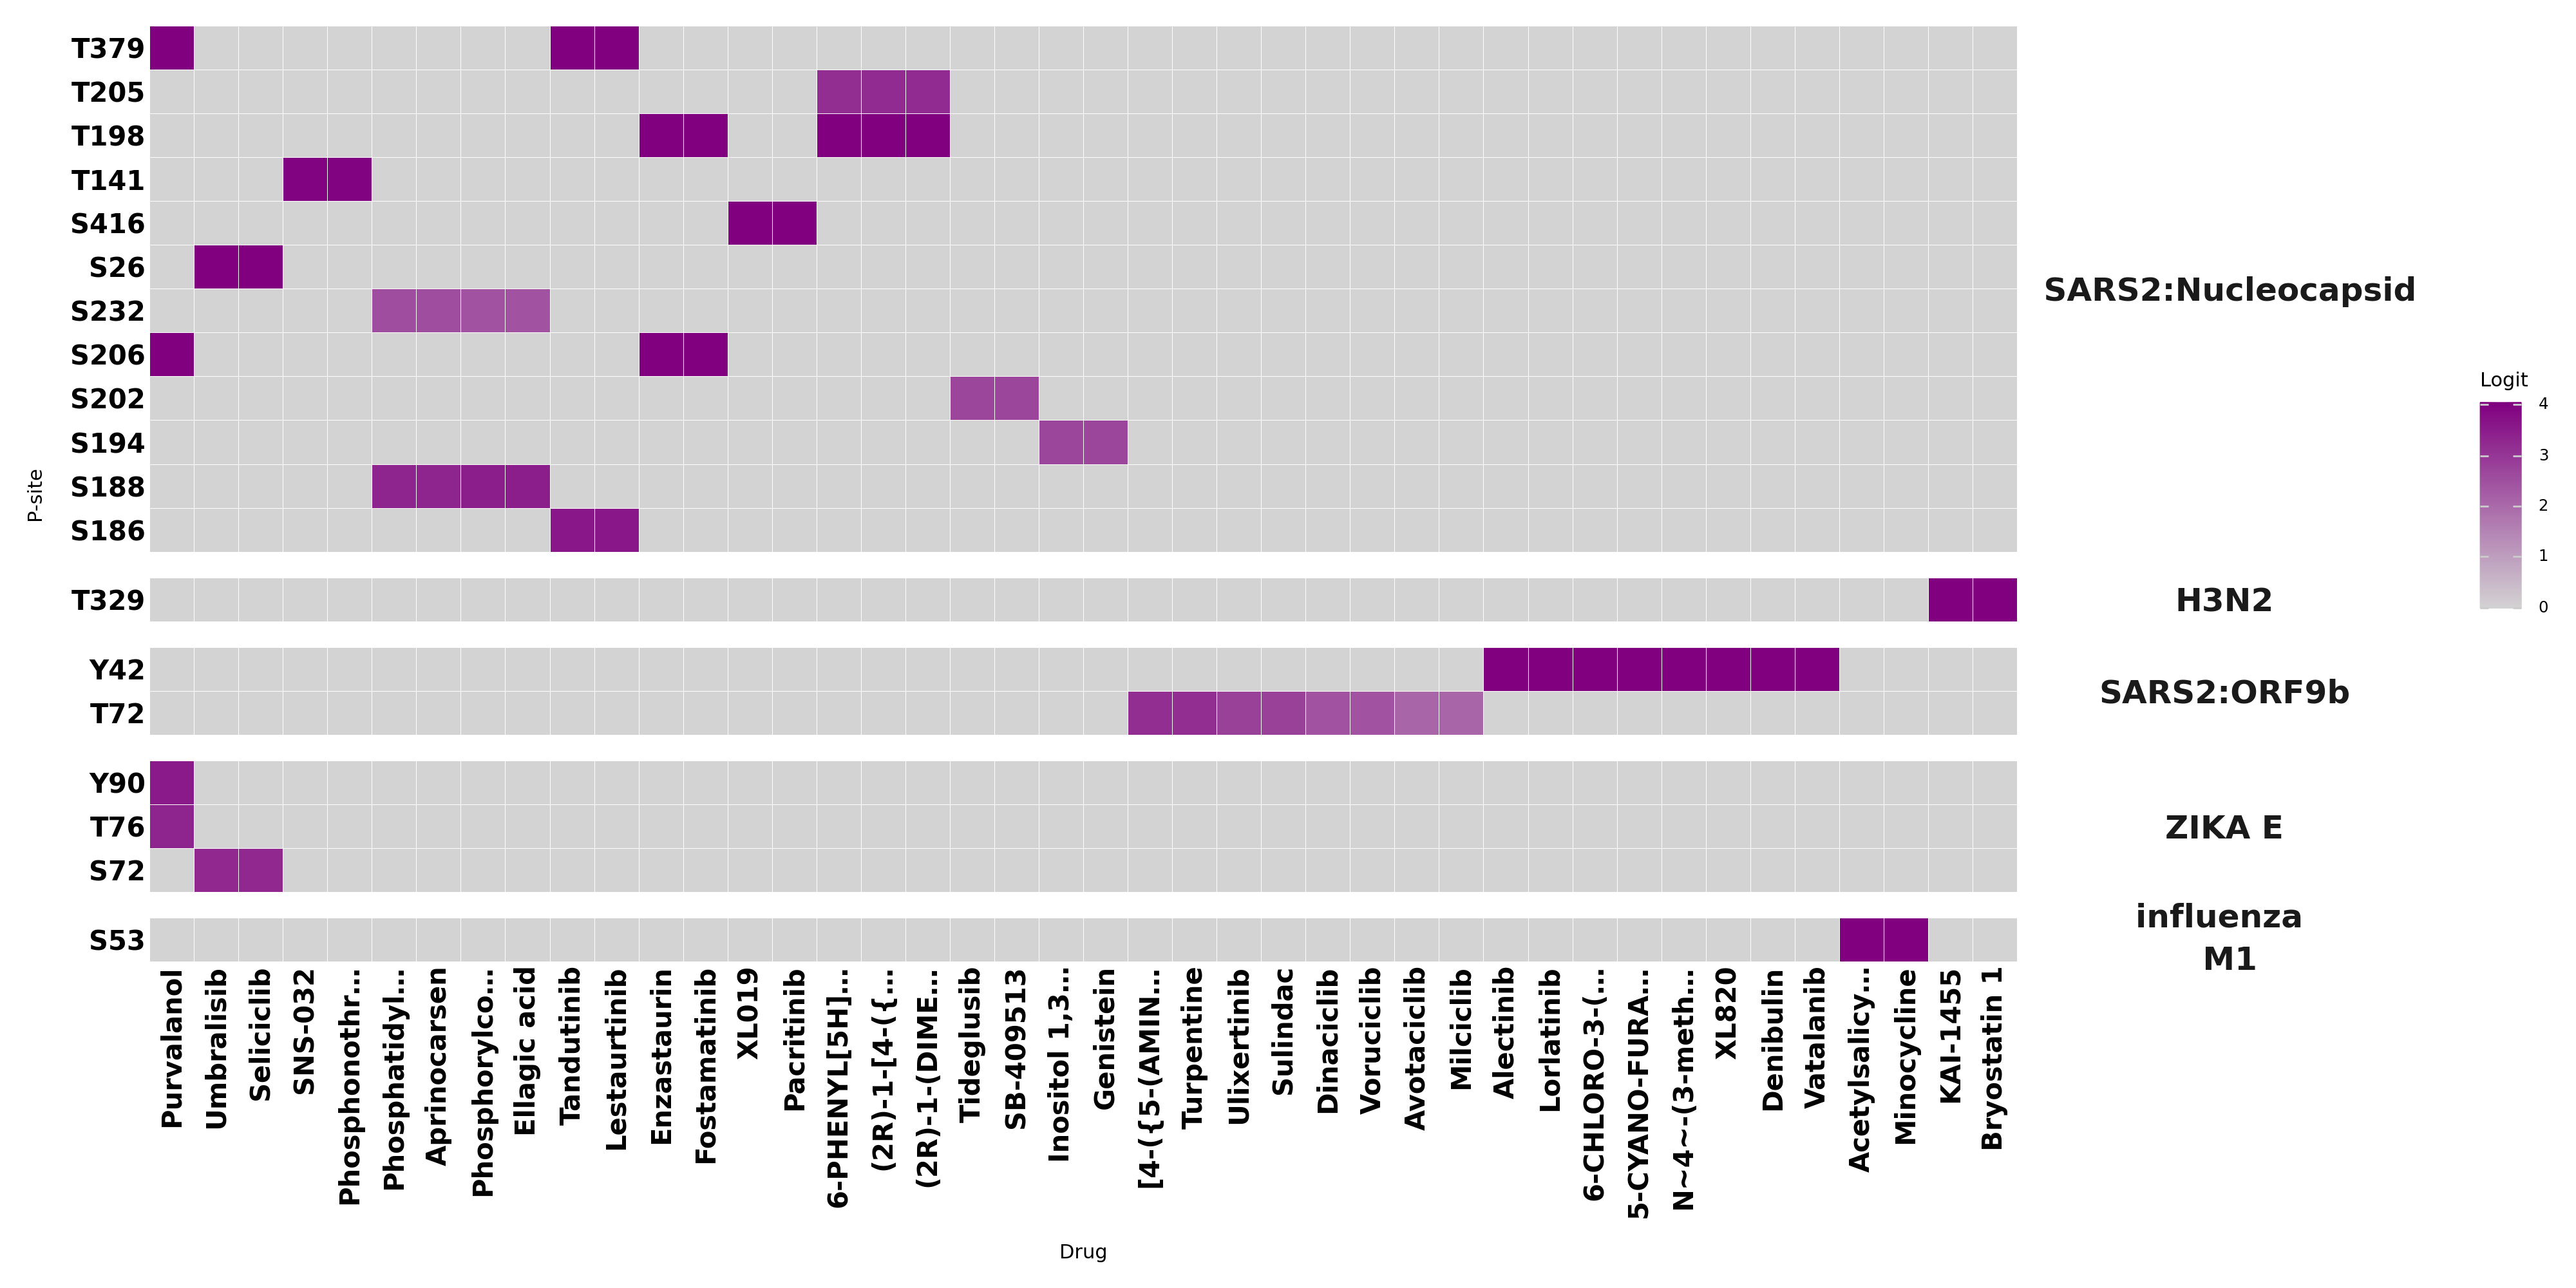

In [119]:
p_drug.show()

In [604]:
p1.save('./eval_figs/eval_virus_dms_kinase_psite_demo.png')
p2.save('./eval_figs/eval_virus_dms_drug_kinase_demo.png')
p_drug.save('./eval_figs/eval_virus_dms_drug_psite_demo.png')

In [130]:
# The "magic" flag for editable TrueType fonts
import matplotlib as mpl
c
p1.save('./eval_figs/eval_virus_dms_kinase_psite_demo.pdf')
p2.save('./eval_figs/eval_virus_dms_drug_kinase_demo.pdf')
p_drug.save('./eval_figs/eval_virus_dms_drug_psite_demo.pdf')

In [590]:
# p1.save('./eval_figs/eval_virus_dms_kinase_psite.png')
# p2.save('./eval_figs/eval_virus_dms_drug_kinase.png')
# p_drug.save('./eval_figs/eval_virus_dms_drug_psite.png')

In [98]:
# p1.save('./eval_figs/eval_virus_dms_kinase_psite_fulldrug.png')
# p2.save('./eval_figs/eval_virus_dms_drug_kinase_fulldrug.png')
# p_drug.save('./eval_figs/eval_virus_dms_drug_psite_fulldrug.png')

In [124]:
(p1 + theme(svg_usefonts=False)).save('./eval_figs/eval_virus_dms_kinase_psite_demo.svg')

In [127]:
(p2 + theme(svg_usefonts=False)).save('./eval_figs/eval_virus_dms_drug_kinase_demo.svg')

In [128]:
(p_drug + theme(svg_usefonts=False)).save('./eval_figs/eval_virus_dms_drug_psite_demo.svg')